In [3]:
import pandas as pd

In [20]:
customers = pd.read_csv('Project 2 files/olist_customers_dataset.csv')
geolocation = pd.read_csv('Project 2 files/olist_geolocation_dataset.csv')
order_items = pd.read_csv('Project 2 files/olist_order_items_dataset.csv')
payments = pd.read_csv('Project 2 files/olist_order_payments_dataset.csv')
reviews = pd.read_csv('Project 2 files/olist_order_reviews_dataset.csv')
orders = pd.read_csv('Project 2 files/olist_orders_dataset.csv')
products = pd.read_csv('Project 2 files/olist_products_dataset.csv')
sellers = pd.read_csv('Project 2 files/olist_sellers_dataset.csv')
translation = pd.read_csv('Project 2 files/product_category_name_translation.csv')



In [95]:
# Merging orders with reviews \ calculating delivery days per order

order_reviews = orders.merge(reviews, on = 'order_id')

order_reviews['order_purchase_timestamp'] = pd.to_datetime(order_reviews['order_purchase_timestamp'])
order_reviews['order_delivered_customer_date'] = pd.to_datetime(order_reviews['order_delivered_customer_date'])

order_reviews['days_to_deliver'] = order_reviews['order_delivered_customer_date'] - order_reviews['order_purchase_timestamp']

order_reviews['days_to_deliver'] = round(order_reviews['days_to_deliver'].dt.total_seconds()/86400, 2)

order_reviews[['review_score', 'days_to_deliver']].head(5)



,review_score,days_to_deliver
0,4,8.44
1,4,13.78
2,5,9.39
3,5,13.21
4,5,2.87


In [87]:
# Calculation correlation between review score and days to deliver

correlation = order_reviews['review_score'].corr(order_reviews['days_to_deliver'])

print('Correlation between review score and days to deliver:', round(correlation,2)

Correlation between review score and days to deliver: -0.33


In [88]:
# Checking for outliers

order_reviews['days_to_deliver'].describe()


count    96359.000000
mean        12.523341
std          9.457567
min          0.530000
25%          6.760000
50%         10.210000
75%         15.690000
max        208.350000
Name: days_to_deliver, dtype: float64

Text(0, 0.5, 'Number of Orders')

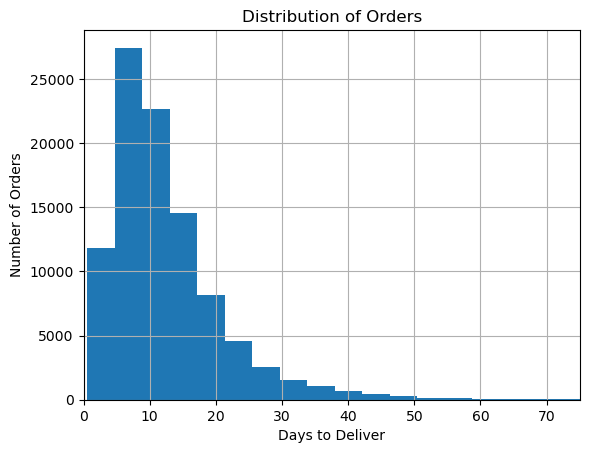

In [89]:
# Distribution Chart
import matplotlib.pyplot as plt

order_reviews['days_to_deliver'].hist(bins = 50)

plt.title('Distribution of Orders')
plt.xlim(0,75)
plt.xlabel('Days to Deliver')
plt.ylabel('Number of Orders')

In [92]:
# Saving file

order_reviews[['review_score', 'days_to_deliver']].to_csv('delivery_days_vs_reviews.csv', index=False)

In [93]:
# Grouping orders by review score

grouped = order_reviews.groupby('review_score')['days_to_deliver'].mean().reset_index()
grouped.to_csv('avg_delivery_by_review_score', index=False)